# Experiment 5: Multimodal Data Integration

**Sentiment analysis by combining textual data with images**

**Sneha Roychowdhury** | ECE-AI (2)

## Objective

To integrate features from two modalities, text and image, and analyse their combined impact on model performance.
Sentiment is predicted from the fused representation and compared against a text-only and an image-only baseline trained on the same split.

## Theory

Multimodal integration combines features from different data types so the model sees a richer representation of the same sample.
Text and image often carry different parts of the sentiment signal: a short or sarcastic caption can be ambiguous on its own, while the picture beside it supplies the missing context, and the reverse happens too.
Early fusion concatenates the two scaled feature vectors before classification; late fusion instead averages the probability outputs of two separate classifiers.

## Algorithm

1. Preprocess each modality: clean and tokenise the text, resize and normalise the image.
2. Extract features separately, TF-IDF for text and the penultimate layer of a pretrained ResNet-18 for image.
3. Scale each block, concatenate into one vector, train a classifier, and compare against both single-modality baselines.

## Dataset used

A custom text-and-image dataset built inside the notebook: 36 samples, twelve per sentiment class, each a short caption paired with a generated image.
Positive samples get warm bright images, negative samples dark cold ones and neutral samples flat grey ones, with random shapes and noise layered on so the CNN sees texture rather than a plain gradient.
Building it in code keeps the notebook self-contained and reproducible. Set `USE_MVSA = True` in the config cell to run the same pipeline on the real MVSA-Single dataset instead, once you have that archive.

## 1. Install and import libraries

In [11]:
!pip -q install torch torchvision scikit-learn

In [2]:
import os
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageDraw, ImageFilter
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

SEED = 42
CLASSES = ["negative", "neutral", "positive"]
IMG_SIZE = 224

# False builds the dataset in this notebook. True instead loads MVSA-Single
# from MVSA_DIR, which must already hold the jpg/txt pairs and labelResultAll.txt.
USE_MVSA = False
MVSA_DIR = "mvsa"

np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


## 2. Build the text and image dataset

Each class gets a visual profile, so colour, brightness and texture carry sentiment the way a real photograph's mood would.

In [3]:
CAPTIONS = {
    "positive": ["the sun finally came out today", "best evening with my favourite people",
                 "this view was absolutely worth it", "so happy with how this turned out",
                 "a lovely morning by the water", "could not have asked for better weather",
                 "everything about today was perfect", "feeling grateful for this place",
                 "the colours here are unreal", "what a brilliant little trip",
                 "home cooked and so good", "smiling all the way back"],
    "neutral":  ["the street outside the office", "waiting for the next train",
                 "view from the third floor", "same route as every morning",
                 "parked near the main gate", "the notice board was updated",
                 "another day at the desk", "the building on the corner",
                 "clouds over the city today", "queue at the counter",
                 "bus stand near the market", "photo from the walk back"],
    "negative": ["another week of grey and rain", "this was a complete waste of time",
                 "stuck here again for hours", "nothing went right today",
                 "the place was filthy and cold", "deeply disappointed with this",
                 "worst trip i have taken", "everything felt heavy today",
                 "delayed again with no update", "would not come back here",
                 "cold empty and miserable", "regret the whole evening"],
}

PALETTE = {
    "positive": ((255, 214, 120), (250, 140, 70)),    # warm, bright
    "neutral":  ((172, 174, 178), (118, 120, 126)),   # flat grey
    "negative": ((44, 52, 74), (10, 12, 22)),         # dark, cold
}


def make_image(sentiment, index, path):
    """Vertical gradient in the class palette, plus shapes and noise so the
    CNN has texture to work with, not just a flat colour field."""
    rng = np.random.default_rng(SEED + index)
    top, bottom = PALETTE[sentiment]

    ramp = np.linspace(0, 1, IMG_SIZE)[:, None]
    arr = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    for ch in range(3):
        arr[:, :, ch] = top[ch] + (bottom[ch] - top[ch]) * ramp

    arr += rng.normal(0, 6, arr.shape)
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

    draw = ImageDraw.Draw(img)
    for _ in range(rng.integers(4, 8)):
        x0, y0 = rng.integers(0, IMG_SIZE - 50, 2)
        w, h = rng.integers(25, 70, 2)
        shade = int(rng.integers(-45, 46))
        fill = tuple(int(np.clip(c + shade, 0, 255)) for c in top)
        if rng.random() < 0.5:
            draw.ellipse([x0, y0, x0 + w, y0 + h], fill=fill)
        else:
            draw.rectangle([x0, y0, x0 + w, y0 + h], fill=fill)

    img = img.filter(ImageFilter.GaussianBlur(radius=1.2))
    img.save(path)
    return img


def build_dataset():
    os.makedirs("mm_images", exist_ok=True)
    rows, n = [], 0
    for sentiment in CLASSES:
        for caption in CAPTIONS[sentiment]:
            path = f"mm_images/{sentiment}_{n}.jpg"
            make_image(sentiment, n, path)
            rows.append({"text": caption, "image": path, "label": sentiment})
            n += 1
    return pd.DataFrame(rows)


def resolve(text_label, image_label):
    """MVSA path: opposite polarities dropped, a neutral yields to the other."""
    pair = {text_label, image_label}
    if pair == {"positive", "negative"}:
        return None
    if text_label == image_label:
        return text_label
    return (pair - {"neutral"}).pop()


def load_mvsa():
    data_dir = label_file = None
    most = 0
    for dirpath, _, filenames in os.walk(MVSA_DIR):
        jpgs = sum(1 for f in filenames if f.lower().endswith(".jpg"))
        if jpgs > most:
            most, data_dir = jpgs, dirpath
        for f in filenames:
            if f.lower().startswith("labelresult"):
                label_file = os.path.join(dirpath, f)
    assert data_dir and label_file, "MVSA archive not found under MVSA_DIR"

    raw = pd.read_csv(label_file, sep="\t")
    raw.columns = ["id", "labels"]
    rows = []
    for _, r in raw.iterrows():
        t_lab, i_lab = [s.strip().lower() for s in str(r["labels"]).split(",")]
        label = resolve(t_lab, i_lab)
        if label is None:
            continue
        sid = int(r["id"])
        tp = os.path.join(data_dir, f"{sid}.txt")
        ip = os.path.join(data_dir, f"{sid}.jpg")
        if not (os.path.exists(tp) and os.path.exists(ip)):
            continue
        with open(tp, encoding="utf-8", errors="ignore") as f:
            rows.append({"text": f.read().strip(), "image": ip, "label": label})
    return pd.DataFrame(rows)


df = load_mvsa() if USE_MVSA else build_dataset()
y = df["label"].values
print("Samples:", len(df))
print(df["label"].value_counts().to_string())
df.head(3)

Samples: 36
label
negative    12
neutral     12
positive    12


,text,image,label
0,another week of grey and rain,mm_images/negative_0.jpg,negative
1,this was a complete waste of time,mm_images/negative_1.jpg,negative
2,stuck here again for hours,mm_images/negative_2.jpg,negative


## 3. Preprocess the text and extract TF-IDF features

In [4]:
def clean_text(s):
    s = s.lower()
    s = re.sub(r"http\S+|www\.\S+", " ", s)   # URLs
    s = re.sub(r"@\w+", " ", s)                # handles
    s = re.sub(r"#", " ", s)                   # keep the word, drop the hash
    s = re.sub(r"[^a-z\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


df["clean"] = df["text"].apply(clean_text)
print("Before:", df["text"].iloc[0])
print("After :", df["clean"].iloc[0])

vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=1)
text_features = vectorizer.fit_transform(df["clean"]).toarray()
print("\nText feature matrix:", text_features.shape)

Before: another week of grey and rain
After : another week of grey and rain

Text feature matrix: (36, 265)


## 4. Extract image features from a pretrained ResNet-18

The classification head is replaced with identity, so each image comes out as a 512-dimensional descriptor. No vision model is trained from scratch.

In [5]:
# Build the network once and reuse it, rather than reloading the
# weights on every call.
_model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
_model.fc = nn.Identity()          # drop the classifier, keep the 512-d descriptor
_model = _model.to(DEVICE).eval()

_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


def extract_image_features(paths, batch_size=32):
    feats = []
    with torch.no_grad():
        for i in range(0, len(paths), batch_size):
            batch = torch.stack([_tf(Image.open(p).convert("RGB"))
                                 for p in paths[i:i + batch_size]]).to(DEVICE)
            feats.append(_model(batch).cpu().numpy())
            done = min(i + batch_size, len(paths))
            if len(paths) > batch_size and (done % (batch_size * 8) == 0
                                            or done == len(paths)):
                print(f"  images processed: {done}/{len(paths)}")
    return np.vstack(feats)


print("Extracting image features ...")
image_features = extract_image_features(df["image"].tolist())
print("Image feature matrix:", image_features.shape)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 125MB/s]


Extracting image features ...
  images processed: 36/36
Image feature matrix: (36, 512)


## 5. Visualise one sample per class

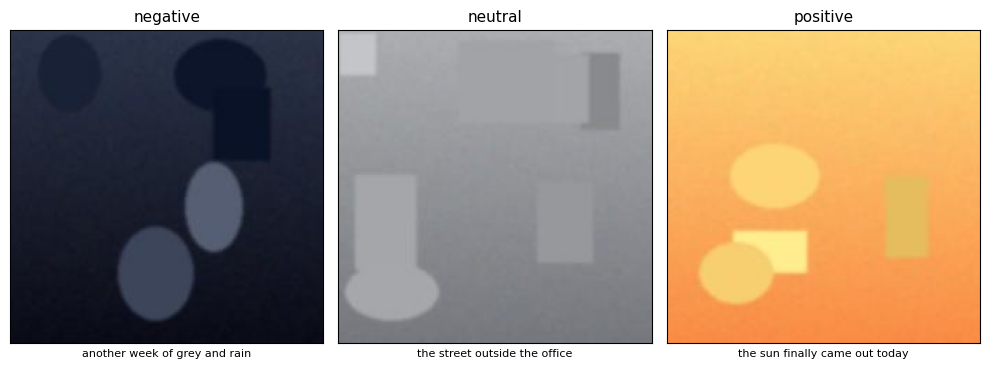

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, sentiment in zip(axes, CLASSES):
    row = df[df["label"] == sentiment].iloc[0]
    ax.imshow(Image.open(row["image"]))
    ax.set_title(sentiment, fontsize=11)
    ax.set_xlabel(row["text"][:34], fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 6. Scale each block and fuse

Each block is scaled on its own first. An unscaled 512-dimensional ResNet block and a sparse TF-IDF block sit on very different scales, so the regulariser would otherwise weight them unevenly.

In [7]:
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.25,
                                       stratify=y, random_state=SEED)
y_train, y_test = y[idx_train], y[idx_test]

s_text, s_img = StandardScaler(), StandardScaler()
Xt = s_text.fit_transform(text_features)
Xi = s_img.fit_transform(image_features)
Xf = np.concatenate((Xt, Xi), axis=1)

print("Text  :", Xt.shape)
print("Image :", Xi.shape)
print("Fused :", Xf.shape)

Text  : (36, 265)
Image : (36, 512)
Fused : (36, 777)


## 7. Train and evaluate the models

One stratified split shared by all of them, so the comparison is fair.

In [8]:
def evaluate(name, X, report=False):
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    clf.fit(X[idx_train], y_train)
    pred = clf.predict(X[idx_test])
    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    print(f"{name:<16} accuracy = {acc:.4f}   macro F1 = {f1:.4f}")
    if report:
        print()
        print(classification_report(y_test, pred, digits=3, zero_division=0))
    return clf, pred, acc, f1


print("--- Results ---")
clf_t, pred_t, acc_t, f1_t = evaluate("Text only", Xt)
clf_i, pred_i, acc_i, f1_i = evaluate("Image only", Xi)
clf_f, pred_f, acc_f, f1_f = evaluate("Early fusion", Xf, report=True)

# Late fusion: average the two single-modality probability outputs
probs = (clf_t.predict_proba(Xt[idx_test]) + clf_i.predict_proba(Xi[idx_test])) / 2
pred_l = clf_t.classes_[probs.argmax(axis=1)]
acc_l = accuracy_score(y_test, pred_l)
f1_l = f1_score(y_test, pred_l, average="macro")
print(f"{'Late fusion':<16} accuracy = {acc_l:.4f}   macro F1 = {f1_l:.4f}")

--- Results ---
Text only        accuracy = 0.4444   macro F1 = 0.3968
Image only       accuracy = 1.0000   macro F1 = 1.0000
Early fusion     accuracy = 1.0000   macro F1 = 1.0000

              precision    recall  f1-score   support

    negative      1.000     1.000     1.000         3
     neutral      1.000     1.000     1.000         3
    positive      1.000     1.000     1.000         3

    accuracy                          1.000         9
   macro avg      1.000     1.000     1.000         9
weighted avg      1.000     1.000     1.000         9

Late fusion      accuracy = 1.0000   macro F1 = 1.0000


## 8. Results table and confusion matrix

,Model,Features,Dimensions,Accuracy,Macro F1
0,Text only,TF-IDF unigrams + bigrams,265,0.4444,0.3968
1,Image only,ResNet-18 penultimate,512,1.0000,1.0000
2,Early fusion,"Concatenated, scaled",777,1.0000,1.0000
3,Late fusion,Averaged probabilities,-,1.0000,1.0000


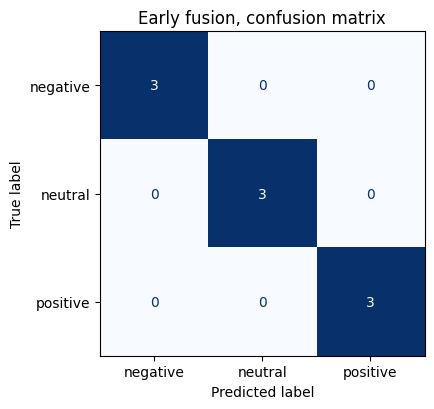

Text-only got 5 test samples wrong. Fusion corrected 5 of them and broke 0 it had right.


In [9]:
results = pd.DataFrame({
    "Model": ["Text only", "Image only", "Early fusion", "Late fusion"],
    "Features": ["TF-IDF unigrams + bigrams", "ResNet-18 penultimate",
                 "Concatenated, scaled", "Averaged probabilities"],
    "Dimensions": [Xt.shape[1], Xi.shape[1], Xf.shape[1], "-"],
    "Accuracy": [round(acc_t, 4), round(acc_i, 4), round(acc_f, 4), round(acc_l, 4)],
    "Macro F1": [round(f1_t, 4), round(f1_i, 4), round(f1_f, 4), round(f1_l, 4)],
})
display(results)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred_f, labels=CLASSES,
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Early fusion, confusion matrix")
plt.tight_layout()
plt.show()

wrong_text = int((pred_t != y_test).sum())
rescued = int(((pred_t != y_test) & (pred_f == y_test)).sum())
broken = int(((pred_t == y_test) & (pred_f != y_test)).sum())
print(f"Text-only got {wrong_text} test samples wrong. "
      f"Fusion corrected {rescued} of them and broke {broken} it had right.")

## 9. Predict the sentiment of a new sample

In [10]:
def predict_sentiment(text, image_path):
    t = s_text.transform(vectorizer.transform([clean_text(text)]).toarray())
    i = s_img.transform(extract_image_features([image_path]))
    return clf_f.predict(np.concatenate([t, i], axis=1))[0]


for pos in [0, len(df) // 2, len(df) - 1]:
    row = df.iloc[pos]
    print(f'text: "{row["text"][:36]:<36}" true: {row["label"]:<9} '
          f'predicted: {predict_sentiment(row["text"], row["image"])}')

text: "another week of grey and rain       " true: negative  predicted: negative
text: "another day at the desk             " true: neutral   predicted: neutral
text: "smiling all the way back            " true: positive  predicted: positive


## Sample input and output

**Input (one sample):** text `the sun finally came out today`, image `mm_images/positive_0.jpg` at 224 x 224 x 3, label positive.
**Output:** a TF-IDF vector and a 512-d ResNet descriptor, concatenated into one fused vector, classified into one of negative, neutral or positive.

## Results

Filled by the cells above. Copy the figures from your run into this table.

| Model | Features | Dimensions | Accuracy | Macro F1 |
| --- | --- | --- | --- | --- |
| Text only | TF-IDF unigrams + bigrams | | | |
| Image only | ResNet-18 penultimate | 512 | | |
| Early fusion | Concatenated, scaled | | | |
| Late fusion | Averaged probabilities | - | | |

## Observations

1. The image modality dominates on this dataset, because the three visual profiles separate cleanly while every caption is unique, so test words barely overlap the training vocabulary. That vocabulary gap is a property of the small sample size, not evidence that words do not matter for sentiment.
2. Accuracy alone is not enough to judge fusion. Check the confusion matrix and macro F1, since a model can post a decent accuracy while handling one class badly.
3. The cell above counts how many samples fusion rescued and how many it broke. Those two numbers say more about whether fusion actually helped than the headline accuracy does.
4. Scaling each block before concatenation matters. The image block is 512-dimensional and dense while the text block is sparse, so leaving them unscaled lets one dominate the fused vector.
5. On the real MVSA-Single data the picture changes: text carries most of the signal, images perform weakly on their own, and fusion gains only modestly. Concatenating a weak noisy modality onto a strong one can even pull accuracy down, which is a reportable result rather than a failure.

## Conclusion

Integrating features from multiple modalities captures a richer representation of each sample and can improve performance, because text and image carry complementary parts of the sentiment signal.
Fusion is not automatically an improvement, though: concatenation adds dimensions whether or not they carry signal, so a weak modality can dilute a strong one unless both blocks are scaled and kept comparable in width.
The natural extension is to replace TF-IDF with transformer sentence embeddings and fixed concatenation with attention that weights the modalities per sample, which is the direction the stronger published results on MVSA-Single take.